# Pulsed-Latch Pipelines: Timing Repair and Energy Tradeoffs
**Michael Ibrahim, IEEE Member**

**Contents:** [Circuit](#circuit) · [Setup](#setup) · [1. Race-through](#race-through) · [2. Repairs](#timing-repairs) · [3. Energy](#energy-comparison) · [Results](#results)

Pulsed latches offer a potential reduction in storage and clocking overhead, but their transparency introduces a race-through constraint: new data can cross two pipeline stages during a single clock pulse. This notebook investigates how the circuitry used to prevent that failure changes the complete implementation's energy cost.

A two-bank, four-bit incrementing pipeline is constructed from IHP SG13G2 standard cells and simulated at transistor level in ngspice. Two timing repairs are compared: inserting noninverting delay cells into the interstage data paths and shortening the locally generated clock pulses. A resettable flip-flop implementation provides a reference under identical stimulus, output loads and operating conditions. Waveform analysis relates transaction correctness to loaded pulse width, data departure and transient glitches. Signed energy is integrated across all seven independent sources, accounting for storage, pulse generation, drivers, logic and padding.

**Default run.** With the supplied circuit settings and workload at TT, 1.2 V, 25 °C, 100 MHz and 5 fF per output, the DFF, padded-latch and shorter-pulse implementations consume **378.77, 504.99 and 410.16 fJ per transaction**, respectively. Both repairs restore the required pipeline behavior, while the DFF reference has the lowest energy in this comparison.

The educational contribution is an executable connection between a timing failure, its physical repair and its energy consequence. Readers can edit pulse generation, padding and input history, regenerate the circuit, and evaluate each design directly from its simulated waveforms.

<a id="circuit"></a>

## Pipeline architecture and timing requirement

An edge-triggered flip-flop captures around its active clock edge, then holds its output. With two banks on the same clock, bank A accepts the new input while bank B accepts the increment of A's **previous** value:

$$
A[n]=\mathrm{input}[n],\qquad B[n]=(A[n-1]+1)\bmod 16.
$$

For example, reset leaves A and B at zero. When the first input is 15 (`1111`), the required outputs are **A = 15 and B = 1**. If B instead stores `(15+1) mod 16 = 0`, the new transaction has crossed the boundary too soon.

A latch behaves differently: **while GATE is high, its output can follow its input**.
Opening both latch banks briefly can let that unwanted same-cycle transfer occur.
The schematic identifies the two latch banks and the delay elements used for timing repair.

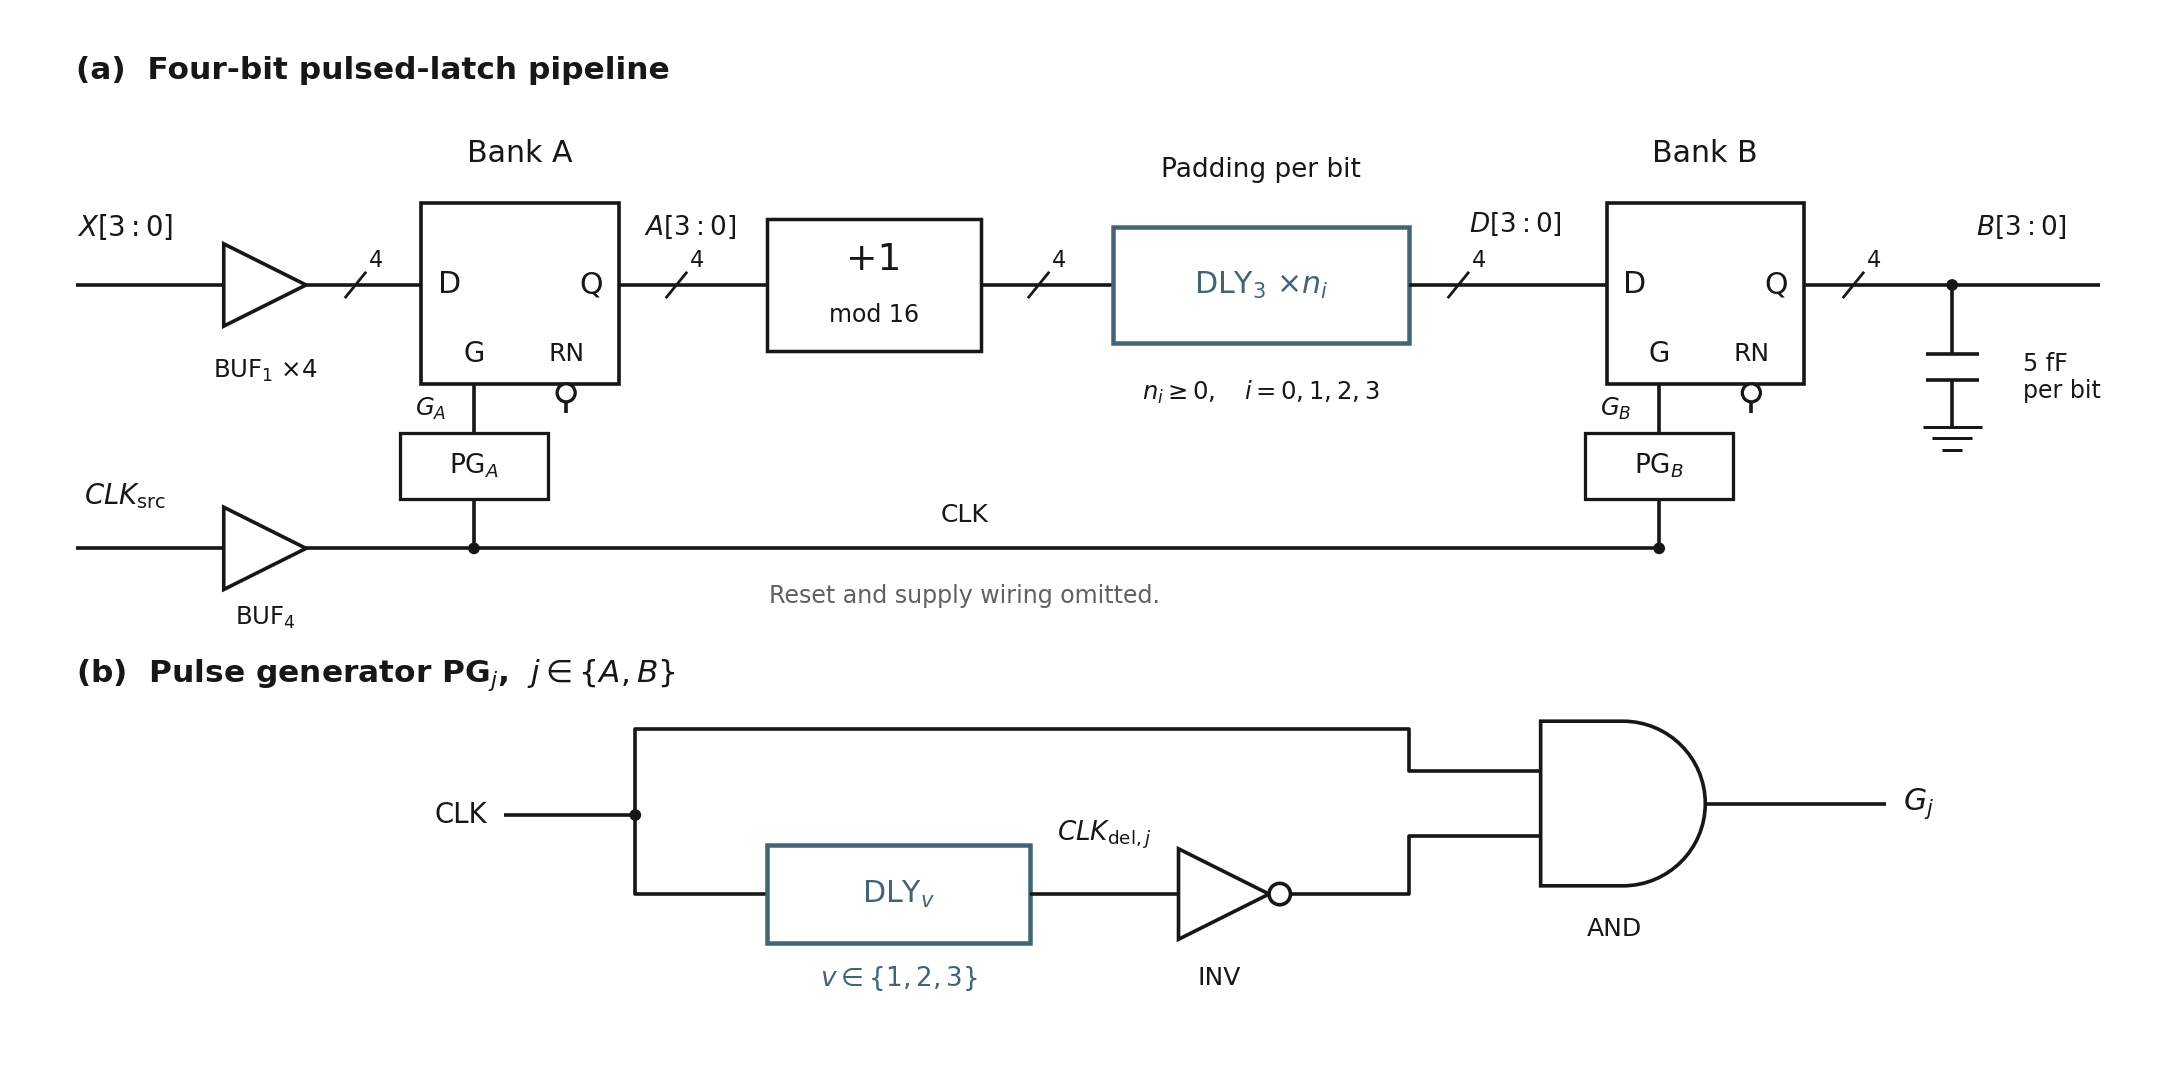

**Figure 1.** Four-bit pulsed-latch pipeline and pulse-generator implementation. Each bank contains four active-high latches with active-low reset. Blue delay elements are the two circuit controls: pulse-cell variant `v` and padding count `n_i` per bit. `DLY_v` denotes `sg13g2_dlygate4sd{v}_1`; padding repeats variant 3. Reset and supply wiring are omitted.

### Timing-repair alternatives

The data path is **A → incrementer → optional delay cells → D of bank B**.
Each bank has its own physical pulse generator driven by the common clock.

| Repair | Event it aims to move | Cost to investigate |
|:--|:--|:--|
| Insert delay cells before B | New data arrives later | Extra switching circuitry and a slower data path |
| Shorten the generated pulse | B closes earlier | Less time to capture the intended data |

The pulse generator implements `GATE = CLK AND NOT(delayed CLK)`. Its delay-cell variant changes the pulse, but the actual width also depends on the loaded circuit. We will measure that width, test whether each repair preserves the transaction, and then count the complete energy cost.

<a id="setup"></a>

## Tools and simulation conditions

Use ngspice 39 or newer with OSDI support, plus a Python notebook kernel containing NumPy, pandas, Matplotlib and IPython. The setup cell installs ngspice when administrator-level `apt-get` is available; otherwise it uses an existing installation.
Set `NGSPICE` to its executable path if it is not found automatically.

<details><summary>Transistor-model setup on different systems</summary>

The model cell downloads the matching precompiled PSP libraries for Windows x64 or Linux x64. For another architecture, set `OSDI_DIR` to compatible
`psp103.osdi` and `psp103_nqs.osdi` libraries for your ngspice build.
This avoids installing a model compiler as part of the lesson.
See [ngspice downloads](https://ngspice.sourceforge.io/download.html) and
[PSP binary packages](https://github.com/dwarning/VA-Models#binary-packages).

</details>

We use **1.2 V, 25 °C, TT**, a **10 ns** period, **50 ps** external transitions and **5 fF** per B output. Inputs finish changing 2 ns before the edge. The flip-flop reference uses the same logic, reset, external drivers and loads.

In [1]:
import os, re, shutil, subprocess
NGSPICE = None  # Optional executable path, for example r'C:\tools\ngspice\bin\ngspice_con.exe'.
NGSPICE = NGSPICE or shutil.which('ngspice_con') or shutil.which('ngspice')
if NGSPICE is None:
    if shutil.which('apt-get') and hasattr(os, 'geteuid') and os.geteuid() == 0:
        subprocess.run(['apt-get', 'update', '-qq'], check=True)
        subprocess.run(['apt-get', 'install', '-y', '-qq', '--no-install-recommends', 'ngspice'], check=True)
        NGSPICE = shutil.which('ngspice')
    else:
        raise RuntimeError('Install ngspice with OSDI support and set NGSPICE to its executable path.')
version = subprocess.check_output([NGSPICE, '--version'], text=True)
match = re.search(r'ngspice-(\d+)', version)
if match is None or int(match[1]) < 39:
    raise RuntimeError('This circuit needs ngspice 39 or newer with OSDI support.')
print(next(line for line in version.splitlines() if 'ngspice-' in line))

** ngspice-42 : Circuit level simulation program


In [2]:
from pathlib import Path
import hashlib, io, platform, re, shutil, subprocess, tarfile, tempfile, time, zipfile
from urllib.request import urlopen
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

In [3]:
PDK_COMMIT = '5e6d592e4002946a4616f798c357f0f3c06cf3b6'
PDK_URL = f'https://raw.githubusercontent.com/IHP-GmbH/IHP-Open-PDK/{PDK_COMMIT}/ihp-sg13g2/'
MODEL_DIR = (Path.cwd() / 'pulse_lab' / 'models').resolve()
MODEL_DIR.mkdir(parents=True, exist_ok=True)

def download(url, destination):
    if not destination.exists():
        with urlopen(url, timeout=90) as response:
            destination.write_bytes(response.read())
    return destination

model_names = ['cornerMOSlv.lib'] + [
    f'sg13g2_moslv_{suffix}.lib'
    for suffix in ('mod', 'parm', 'stat', 'mismatch', 'mod_mismatch')]
for name in model_names:
    download(PDK_URL + 'libs.tech/ngspice/models/' + name, MODEL_DIR / name)
download(PDK_URL + 'libs.ref/sg13g2_stdcell/spice/sg13g2_stdcell.spice',
         MODEL_DIR / 'sg13g2_stdcell.spice')

PosixPath('/content/pulse_lab/models/sg13g2_stdcell.spice')

In [4]:
OSDI_DIR = None  # Optional folder containing both PSP libraries for your ngspice build.
osdi_names = ('psp103.osdi', 'psp103_nqs.osdi')
if OSDI_DIR is not None:
    supplied = Path(OSDI_DIR).expanduser().resolve()
    if not all((supplied / name).is_file() for name in osdi_names):
        raise FileNotFoundError('OSDI_DIR must contain psp103.osdi and psp103_nqs.osdi.')
    for name in osdi_names:
        if (supplied / name) != (MODEL_DIR / name):
            shutil.copy2(supplied / name, MODEL_DIR / name)
else:
    assets = {
        'Linux': ('tar.gz', '79b4f34ee931bd64cffb7f0be46c48d331988981f6f20b783f9ee75ecac42487'),
        'Windows': ('zip', '728cf275f9a722aa40ea8b407f8a267bd4987b5ab86ce936b4e0733ecb5d4266')}
    if platform.system() not in assets or platform.machine().lower() not in ('x86_64', 'amd64'):
        raise RuntimeError('Automatic PSP downloads are available for Linux/Windows x64. '
                           'Set OSDI_DIR to PSP libraries compatible with your ngspice build.')
    suffix, expected_hash = assets[platform.system()]
    binary_url = ('https://github.com/dwarning/VA-Models/releases/download/v2.2/'
                  f'VA-Models-osdilibs.{suffix}')
    archive = download(binary_url, MODEL_DIR / f'psp-libraries.{suffix}').read_bytes()
    if hashlib.sha256(archive).hexdigest() != expected_hash:
        raise RuntimeError('Model download checksum mismatch; remove the cached archive and retry.')
    if suffix == 'zip':
        with zipfile.ZipFile(io.BytesIO(archive)) as package:
            binaries = {name: package.read('osdilibs/' + name) for name in osdi_names}
    else:
        with tarfile.open(fileobj=io.BytesIO(archive), mode='r:gz') as package:
            binaries = {name: package.extractfile('osdilibs/' + name).read() for name in osdi_names}
    for name, binary in binaries.items():
        (MODEL_DIR / name).write_bytes(binary)
print('IHP cells and PSP transistor models are ready.')

IHP cells and PSP transistor models are ready.


### Circuit construction
These three definitions connect the actual cells: pulse generation, incrementer and padding, then the two storage banks. `pads` is always ordered **(bit 0, bit 1, bit 2, bit 3)**. All internal cells draw from the measured VDD source. The experiment controls later select the pulse variant and padding counts.

In [5]:
def pulse_generator(bank, variant):
    """GATE = CLK AND NOT(delayed CLK), using physical standard cells."""
    return [
        f'Xpdelay_{bank} clk_del_{bank} clk vdd 0 sg13g2_dlygate4sd{variant}_1',
        f'Xpinv_{bank} clk_del_n_{bank} clk_del_{bank} vdd 0 sg13g2_inv_1',
        f'Xpand_{bank} gate_{bank} clk clk_del_n_{bank} vdd 0 sg13g2_and2_1',
    ]

In [6]:
def incrementer(pads):
    lines = [
        'Xinc0 inc0 a0 vdd 0 sg13g2_inv_1',
        'Xinc1 inc1 a1 a0 vdd 0 sg13g2_xor2_1',
        'Xcarry2 carry2 a1 a0 vdd 0 sg13g2_and2_1',
        'Xinc2 inc2 a2 carry2 vdd 0 sg13g2_xor2_1',
        'Xcarry3 carry3 a2 carry2 vdd 0 sg13g2_and2_1',
        'Xinc3 inc3 a3 carry3 vdd 0 sg13g2_xor2_1',
    ]
    for bit, count in enumerate(pads):
        previous = f'inc{bit}'
        for stage in range(count):
            following = f'pad{bit}_{stage}'
            lines.append(f'Xpad{bit}_{stage} {following} {previous} vdd 0 sg13g2_dlygate4sd3_1')
            previous = following
        lines.append(f'Vwire{bit} d{bit} {previous} 0')
    return lines

In [7]:
VDD, PERIOD, FIRST_EDGE, SLEW = 1.2, 10e-9, 20e-9, 50e-12

def pipeline(architecture, pulse_variant, pads):
    lines = [f'VDD vdd 0 {VDD}',
             'Xclk clk clk_src vdd 0 sg13g2_buf_4',
             'Xrst reset_b reset_src vdd 0 sg13g2_buf_4']
    for bit in range(4):
        lines.append(f'Xinput{bit} x{bit} x{bit}_src vdd 0 sg13g2_buf_1')
    for bank in ('a', 'b'):
        if architecture == 'latch':
            lines += pulse_generator(bank, pulse_variant)
        else:
            lines.append(f'Vclock_{bank} gate_{bank} clk 0')
        for bit in range(4):
            d = f'x{bit}' if bank == 'a' else f'd{bit}'
            if architecture == 'latch':
                pins = f'{bank}{bit} {d} gate_{bank} reset_b'
                cell = 'sg13g2_dlhrq_1'
            else:
                pins = f'{bank}{bit} gate_{bank} {d} reset_b'
                cell = 'sg13g2_dfrbpq_1'
            lines.append(f'X{bank}{bit} {pins} vdd 0 {cell}')
    lines += [f'Cload{bit} b{bit} 0 5f' for bit in range(4)]
    return lines + incrementer(pads)

### Simulation and waveform interpretation
The following definitions create the input waveforms, simulate the circuit, and read its traces. They also implement the timing and energy calculations used later.
You can expand the setup cells to inspect them. After running these definitions, continue to [Experiment 1: race-through](#race-through).

A valid 0 is at or below 20% VDD; a valid 1 is at or above 80% VDD. The checker requires A and B to be correct throughout **+3 to +9.9 ns** after each edge.
A brief correct pulse is therefore insufficient. Rows following a failure are
marked because they no longer start from a verified preceding transaction.

In [8]:
def pwl(points):
    return 'PWL(' + ' '.join(f'{t:.12g} {v:.12g}' for t, v in points) + ')'

def sources(inputs):
    edges = FIRST_EDGE + np.arange(len(inputs)) * PERIOD
    stop = edges[-1] + PERIOD
    clock = [(0, 0)]
    for edge in edges:
        clock += [(edge-SLEW/2, 0), (edge+SLEW/2, VDD),
                  (edge+PERIOD/2-SLEW/2, VDD), (edge+PERIOD/2+SLEW/2, 0)]
    lines = ['Vclk clk_src 0 ' + pwl(clock + [(stop, 0)]),
             'Vreset reset_src 0 ' + pwl([(0, 0), (5e-9-SLEW/2, 0),
                                         (5e-9+SLEW/2, VDD), (stop, VDD)])]
    for bit in range(4):
        previous, points = 0, [(0, 0)]
        for edge, word in zip(edges, inputs):
            value = ((word >> bit) & 1) * VDD
            if value != previous:
                points += [(edge-2e-9-SLEW, previous), (edge-2e-9, value)]
            previous = value
        lines.append(f'Vx{bit} x{bit}_src 0 ' + pwl(points + [(stop, previous)]))
    return lines, edges, stop

In [9]:
def simulate(inputs, pulse_variant=3, pads=(0, 0, 0, 0), architecture='latch', step_ps=10):
    inputs, pads = tuple(inputs), tuple(pads)
    if architecture not in ('latch', 'dff') or pulse_variant not in (1, 2, 3):
        raise ValueError('Choose latch/dff and pulse variant 1, 2 or 3.')
    if len(pads) != 4 or any(type(n) is not int or not 0 <= n <= 16 for n in pads):
        raise ValueError('Padding needs four integer counts, each 0..16.')
    if not inputs or any(type(n) is not int or not 0 <= n <= 15 for n in inputs):
        raise ValueError('Inputs must be four-bit integers (0..15).')
    if not np.isfinite(step_ps) or not 0 < step_ps <= 20:
        raise ValueError('Choose a finite maximum timestep between 0 and 20 ps.')
    stimulus, edges, stop = sources(inputs)
    nodes = ['clk_src', 'reset_src', 'gate_a', 'gate_b', 'carry2', 'carry3']
    nodes += [f'{p}{b}' for p in ('a', 'inc', 'd', 'b') for b in range(4)]
    nodes += [f'x{b}_src' for b in range(4)]
    if architecture == 'latch':
        nodes += ['clk_del_a', 'clk_del_b', 'clk_del_n_a', 'clk_del_n_b']
    vectors = [f'v({n})' for n in nodes] + [f'i({s})' for s in ('vdd', 'vclk', 'vreset', 'vx0', 'vx1', 'vx2', 'vx3')]
    deck = ['Live pulsed-latch experiment', '.control', 'set osdi_enabled']
    deck += [f'pre_osdi models/{name}' for name in ('psp103.osdi', 'psp103_nqs.osdi')]
    deck += ['.endc', '.lib "models/cornerMOSlv.lib" mos_tt',
             '.include "models/sg13g2_stdcell.spice"', '.temp 25',
             '.options reltol=1e-4 abstol=1e-14 vntol=1e-7']
    deck += pipeline(architecture, pulse_variant, pads) + stimulus
    deck += ['.save ' + ' '.join(vectors), '.control', 'set wr_singlescale',
             'set wr_vecnames', 'set numdgt=16',
             f'tran {step_ps}p {stop:.12g} 0 {step_ps}p',
             'wrdata trace.tsv ' + ' '.join(vectors), 'quit', '.endc', '.end']
    return execute_deck(deck, inputs, edges, pulse_variant, pads, architecture, step_ps)

In [10]:
def execute_deck(deck, inputs, edges, pulse_variant, pads, architecture, step_ps):
    run_root = MODEL_DIR.parent / 'runs'
    run_root.mkdir(exist_ok=True)
    folder = Path(tempfile.mkdtemp(prefix='run-', dir=run_root))
    shutil.copytree(MODEL_DIR, folder / 'models',
                    ignore=shutil.ignore_patterns('*.zip', '*.tar.gz'))
    (folder / 'circuit.cir').write_text('\n'.join(deck) + '\n')
    started = time.perf_counter()
    result = subprocess.run([NGSPICE, '-b', 'circuit.cir'], cwd=folder,
                            capture_output=True, text=True, timeout=600,
                            creationflags=getattr(subprocess, 'CREATE_NO_WINDOW', 0))
    log = result.stdout + result.stderr
    (folder / 'ngspice.log').write_text(log)
    if result.returncode or not (folder / 'trace.tsv').exists():
        raise RuntimeError(f'SPICE failed. Log: {folder / "ngspice.log"}\n{log[-2000:]}')
    trace = pd.read_csv(folder / 'trace.tsv', sep=r'\s+')
    trace.columns = [c[2:-1] if c.startswith('v(') else c for c in trace.columns]
    if len(trace) < 2 or not np.isfinite(trace.to_numpy()).all():
        raise RuntimeError('SPICE produced an invalid trace; inspect its log.')
    print(f'Fresh {architecture} simulation: pulse={pulse_variant}, padding={pads}, '
          f'{len(inputs)} inputs, {time.perf_counter()-started:.1f} s')
    return dict(trace=trace, inputs=inputs, edges=edges, vdd=VDD, period=PERIOD,
                pulse_variant=pulse_variant, pads=pads, architecture=architecture,
                step_ps=step_ps, folder=folder)

In [11]:
def checked_index(value, length, name):
    if isinstance(value, (bool, np.bool_)) or not isinstance(value, (int, np.integer)):
        raise ValueError(f'{name} must be an integer from 0 to {length-1}.')
    if not 0 <= value < length:
        raise ValueError(f'{name} must be an integer from 0 to {length-1}.')
    return int(value)


def interval_values(run, column, start, end):
    data = run['trace']
    time = data['time'].to_numpy()
    values = data[column].to_numpy()
    if end <= start or start < time[0] or end > time[-1]:
        raise ValueError('The trace must cover the complete requested interval.')
    if not np.isfinite(values).all():
        raise ValueError('Nonfinite waveform values cannot be measured.')
    selected = time[(time > start) & (time < end)]
    sample_time = np.r_[start, selected, end]
    return sample_time, np.interp(sample_time, time, values)


def valid_level(values, bit, vdd):
    return values >= 0.8*vdd if bit else values <= 0.2*vdd


def observed_word(values, vdd):
    bits = [0 if value <= 0.2*vdd else 1 if value >= 0.8*vdd else None
            for value in values]
    return None if None in bits else sum(bit << index for index, bit in enumerate(bits))


def reset_passes(run):
    return all(np.all(interval_values(run, f'{bank}{bit}', 2e-9, 4e-9)[1]
                         <= 0.2*run['vdd'])
               for bank in ('a', 'b') for bit in range(4))

In [12]:
def transaction_table(run):
    rows, old_a = [], 0
    prepared = reset_passes(run)
    for cycle, (edge, value) in enumerate(zip(run['edges'], run['inputs'])):
        expected = {'a': value, 'b': (old_a + 1) % 16}
        row = {'cycle': cycle, 'input': value, 'preparation_valid': prepared}
        for bank in ('a', 'b'):
            signals = [interval_values(run, f'{bank}{bit}', edge+3e-9,
                                       edge+run['period']-0.1e-9)[1]
                       for bit in range(4)]
            row['expected_'+bank.upper()] = expected[bank]
            row['observed_'+bank.upper()] = observed_word([y[0] for y in signals], run['vdd'])
            row[bank.upper()+'_sustained'] = all(
                np.all(valid_level(y, (expected[bank] >> bit) & 1, run['vdd']))
                for bit, y in enumerate(signals))
        row['correct'] = bool(row['A_sustained'] and row['B_sustained'])
        rows.append(row)
        prepared = bool(prepared and row['correct'])
        old_a = value
    table = pd.DataFrame(rows)
    table.attrs['reset_passed'] = reset_passes(run)
    table.attrs['passed'] = bool(prepared and len(rows) == len(run['inputs']) > 0)
    table.attrs['scope'] = ('Valid levels from edge+3 ns through next edge-0.1 ns; '
                            'later rows after failed preparation are not independent successes.')
    return table

In [13]:
def crossing_times(time, values, threshold, rising=True):
    above = values > threshold
    indices = np.flatnonzero((~above[:-1] & above[1:]) if rising
                            else (above[:-1] & ~above[1:]))
    return [float(time[k] + (threshold-values[k])/(values[k+1]-values[k])
                  * (time[k+1]-time[k])) for k in indices]


def first_departure(run, node, old_bit, start, end):
    old_bit = checked_index(old_bit, 2, 'old_bit')
    time, values = interval_values(run, node, start, end)
    valid = valid_level(values, old_bit, run['vdd'])
    if not valid[0]:
        detail = ('opposite valid level' if valid_level(values[0], 1-old_bit, run['vdd'])
                  else 'between the valid logic levels')
        return None, f'old value invalid at window start ({detail})'
    indices = np.flatnonzero(valid[:-1] & ~valid[1:])
    if not len(indices):
        return None, 'no departure observed through window end'
    k = indices[0]
    threshold = (0.8 if old_bit else 0.2)*run['vdd']
    event = time[k] + (threshold-values[k])/(values[k+1]-values[k])*(time[k+1]-time[k])
    return float(event), 'observed departure, including any returning glitch'

In [14]:
def gate_events(time, gate, vdd):
    rises = crossing_times(time, gate, 0.5*vdd, True)
    falls = crossing_times(time, gate, 0.5*vdd, False)
    single = len(rises) == len(falls) == 1 and rises[0] < falls[0]
    if len(rises) > 1 or len(falls) > 1:
        status = 'ambiguous crossings: more than one pulse'
    elif not rises and not falls:
        status = ('missing pulse' if max(gate) <= 0.2*vdd else
                  'incomplete pulse: gate stays high' if min(gate) > 0.5*vdd else
                  'insufficient logic levels: no resolved pulse')
    elif not single:
        status = 'incomplete pulse: opening or closure not resolved'
    elif max(gate) < 0.8*vdd or max(gate[0], gate[-1]) > 0.2*vdd:
        status = 'insufficient logic levels'
    else:
        status = 'one valid pulse'
    return (rises[0], falls[0], status) if single else (None, None, status)


def separation_status(departure_status, gate_status, architecture):
    if architecture == 'dff':
        return 'not applicable: DFF captures on the rising edge'
    reasons = []
    if departure_status.startswith('old value invalid'):
        reasons.append('invalid old level')
    elif departure_status.startswith('no departure'):
        reasons.append('no departure observed')
    if gate_status != 'one valid pulse':
        reasons.append(gate_status)
    return '; '.join(reasons) if reasons else 'measured event separation'

In [15]:
def timing_table(run, cycle=0):
    cycle = checked_index(cycle, min(len(run['edges']), len(run['inputs'])), 'cycle')
    edge, vdd = run['edges'][cycle], run['vdd']
    start, end = edge-0.5e-9, edge+run['period']-0.1e-9
    time, gate = interval_values(run, 'gate_b', start, end)
    opening, closing, gate_status = gate_events(time, gate, vdd)
    width = (closing-opening)*1e12 if opening is not None else None
    if run['architecture'] == 'dff':
        closing = None
    old_a = 0 if cycle == 0 else run['inputs'][cycle-1]
    old_d = (old_a + 1) % 16
    rows = []
    for bit in range(4):
        departure, status = first_departure(run, f'd{bit}', (old_d >> bit) & 1, start, end)
        rows.append({'bit': bit, 'old_D_bit': (old_d >> bit) & 1,
                     'loaded_gate_width_50_ps': width,
                     'gate_close_ps': (closing-edge)*1e12 if closing is not None else None,
                     'D_departure_ps': (departure-edge)*1e12 if departure is not None else None,
                     'departure_minus_close_ps': (departure-closing)*1e12
                         if departure is not None and closing is not None else None,
                     'departure_status': status, 'gate_status': gate_status,
                     'separation_status': separation_status(status, gate_status, run['architecture']),
                     'observation_end_ps': (end-edge)*1e12})
    table = pd.DataFrame(rows)
    table.attrs['interpretation'] = ('Observed departure-to-close separation, NOT characterized hold margin. '
        'No event means unobserved within this finite window. DFF capture uses the rising edge, '
        'so its falling-edge closure comparison is not applicable. All times use the external rising edge.')
    table.attrs['preparation_valid'] = bool(transaction_table(run).iloc[cycle]['preparation_valid'])
    return table

In [16]:
def timing_view(run, cycle=0):
    table = timing_table(run, cycle)
    rows = []
    for row in table.to_dict('records'):
        end_label = f"+{row['observation_end_ps']:.0f} ps"
        no_departure = (f'not observed through {end_label}'
                        if row['departure_status'].startswith('no departure')
                        else row['departure_status'])
        close_reason = ('not applicable (DFF)' if run['architecture'] == 'dff'
                        else row['gate_status'])
        def value_or_reason(key, reason):
            value = row[key]
            return f'{value:.2f}' if pd.notna(value) else reason
        rows.append({
            'bit': row['bit'], 'old D': row['old_D_bit'],
            'gate width at 50% (ps)': value_or_reason('loaded_gate_width_50_ps', row['gate_status']),
            'gate close (ps)': value_or_reason('gate_close_ps', close_reason),
            'D departure (ps)': value_or_reason('D_departure_ps', no_departure),
            'departure - close (ps)': value_or_reason('departure_minus_close_ps', row['separation_status']),
            'gate status': row['gate_status'], 'D event status': row['departure_status'],
            'separation status': row['separation_status'], 'observed through': end_label})
    view = pd.DataFrame(rows)
    view.attrs.update(table.attrs)
    return view

In [17]:
def transaction_view(run):
    table = transaction_table(run)
    def word(value):
        return 'invalid logic level' if pd.isna(value) else f'{int(value):04b} ({int(value)})'
    rows = []
    for row in table.to_dict('records'):
        outcome = 'PASS' if row['correct'] else 'FAIL'
        if not row['preparation_valid']:
            outcome += '; earlier failure'
        rows.append({'cycle': row['cycle'], 'input': word(row['input']),
                     'A at deadline': word(row['observed_A']),
                     'B required': word(row['expected_B']),
                     'B at deadline': word(row['observed_B']),
                     'whole valid interval': outcome})
    print('Reset:', 'PASS' if table.attrs['reset_passed'] else 'FAIL',
          '| Complete sequence:', 'PASS' if table.attrs['passed'] else 'FAIL')
    return pd.DataFrame(rows).set_index('cycle')

In [18]:
def draw_events(axes, run, bit, cycle, end_ns):
    edge, vdd = run['edges'][cycle], run['vdd']
    row = timing_table(run, cycle).iloc[bit]
    for node, color, label in [('gate_b', '#db8b13', 'GATE'),
                                (f'd{bit}', '#147d92', f'D{bit}')]:
        t, y = interval_values(run, node, edge-0.25e-9, edge+end_ns*1e-9)
        axes[0].plot((t-edge)*1e12, y, color=color, lw=2, label=label)
    t, y = interval_values(run, f'b{bit}', edge-0.25e-9, edge+end_ns*1e-9)
    axes[1].plot((t-edge)*1e12, y, color='#6642a3', lw=2, label=f'B{bit}')
    wanted = row['old_D_bit']
    axes[1].axhline(wanted*vdd, color='#2d853f', ls='--', label=f'required B{bit}={wanted}')
    for key, color, label in [('gate_close_ps', '#b96b00', 'gate closes'),
                                ('D_departure_ps', '#147d92', 'D departs')]:
        value = row[key]
        if pd.notna(value) and -250 <= value <= end_ns*1000:
            axes[0].axvline(value, color=color, ls=':', lw=1.5, label=f'{label}: {value:.0f} ps')
    if pd.isna(row['D_departure_ps']):
        text = ('No D departure in the observation window' if row['departure_status'].startswith('no departure')
                else 'Expected old D level is invalid at window start')
        axes[0].text(0.98, 0.05, text, transform=axes[0].transAxes, ha='right', fontsize=8)
    for ax in axes:
        ax.axhspan(0.2*vdd, 0.8*vdd, color='#8896a4', alpha=0.12)
        ax.set_ylim(-0.09*vdd, 1.12*vdd)
        ax.set_xlim(-250, end_ns*1000)
        ax.set_ylabel('Voltage (V)')
        ax.grid(alpha=0.15)
        ax.legend(loc='upper right', fontsize=8)
    axes[1].set_xlabel('Time from external rising edge (ps)')

In [19]:
def plot_experiment(named_runs, bit=0, cycle=0, end_ns=1.6):
    bit = checked_index(bit, 4, 'bit')
    histories = [tuple(run['inputs']) for _, run in named_runs]
    if any(history != histories[0] for history in histories):
        raise ValueError('Compare the same input history. Rerun the repair after changing INPUTS.')
    if not np.isfinite(end_ns) or end_ns <= 0:
        raise ValueError('end_ns must be positive.')
    columns = len(named_runs)
    panel_width = 4.7 if columns > 2 else 6.5
    fig, axes = plt.subplots(2, columns, figsize=(panel_width*columns, 5.4),
                             sharex=True, sharey=True, squeeze=False, layout='constrained')
    for column, (label, run) in enumerate(named_runs):
        checked_index(cycle, len(run['inputs']), 'cycle')
        if end_ns*1e-9 > run['period']-0.1e-9:
            raise ValueError('Keep the view within this transaction: end_ns <= period in ns minus 0.1.')
        draw_events(axes[:, column], run, bit, cycle, end_ns)
        settings = f"pulse {run['pulse_variant']}, pads {run['pads']}"
        title = f"{label}\n{settings}" if columns > 2 else f"{label}: {settings}"
        axes[0, column].set_title(title, fontsize=11 if columns > 2 else 10)
        if columns > 2:
            axes[0, column].legend(loc='upper center', bbox_to_anchor=(0.5, -0.05),
                                   ncol=2, fontsize=9)
            if column > 0:
                for ax in axes[:, column]:
                    ax.set_ylabel('')
    fig.suptitle(f'Cycle {cycle}, bit {bit}: does new data arrive before the latch closes?', fontsize=12)
    plt.show()
    plt.close(fig)
    return fig

<a id="race-through"></a>

## 1. Race-through in the unrepaired pipeline
The first input, 15, makes the old and new incrementer results visibly different:
old A = 0 gives `0001`, while new A = 15 gives `0000`.
Run the wide pulse without padding. Compare the required and observed B words, then follow bit 0 through the plot.

The last table column checks the whole required interval; the displayed words are samples at its +3 ns start. Later, change `INPUTS` here and rerun both repair cells to investigate another history.

In [20]:
INPUTS = (15, 0, 1)
failure = simulate(INPUTS, pulse_variant=3, pads=(0, 0, 0, 0))
display(transaction_view(failure))

Fresh latch simulation: pulse=3, padding=(0, 0, 0, 0), 3 inputs, 23.9 s
Reset: PASS | Complete sequence: FAIL


,input,A at deadline,B required,B at deadline,whole valid interval
cycle,,,,,
0,1111 (15),1111 (15),0001 (1),0000 (0),FAIL
1,0000 (0),0000 (0),0000 (0),0001 (1),FAIL; earlier failure
2,0001 (1),0001 (1),0001 (1),0000 (0),FAIL; earlier failure


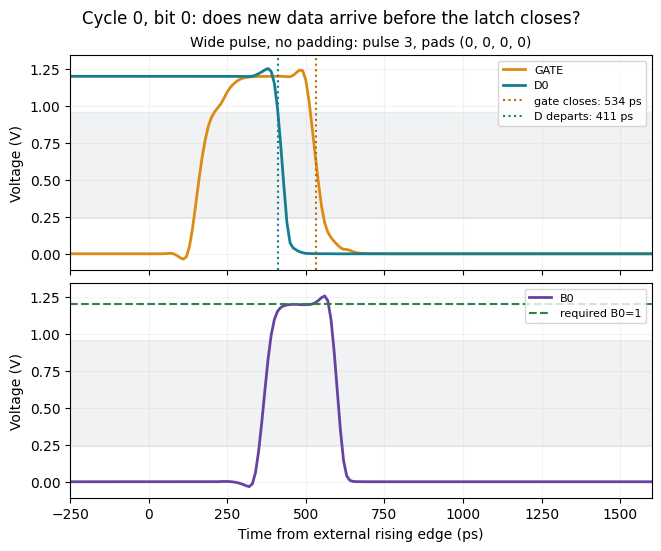

First transaction: FAIL | Required B: 1 | Observed B: 0


In [21]:
_ = plot_experiment([('Wide pulse, no padding', failure)], bit=0, cycle=0)
first = transaction_table(failure).iloc[0]
print('First transaction:', 'PASS' if first['correct'] else 'FAIL',
      '| Required B:', first['expected_B'], '| Observed B:', first['observed_B'])

For the default input, D0 begins high because it represents old A + 1.
After A changes, D0 falls while B's gate is still open. B0 initially reaches the required high level, then follows the new low value and stores the wrong transaction.

The two event markers expose the mechanism: **new data departs before the gate closes**. The plots zoom into the first 1.6 ns; the table checks that the result also remains correct during the later required interval.

<a id="timing-repairs"></a>

## 2. Data-delay and pulse-width repairs

**Delay the data.** Keep the wide pulse and insert padding `(2,1,1,1)`. This adds two delay cells on bit 0 and one on each other bit. New data should move later while gate closure changes little.

**Close earlier.** Remove all padding and use pulse variant 1. This aims to preserve the old result by closing B sooner. The pulse must still last long enough to capture it.

Each of the next two cells runs SPICE. Change `PAD_STAGES` or `PULSE_DELAY_CELL` and rerun the corresponding cell. Both repairs use the baseline's exact input history, so the waveform comparison isolates the circuit change.

In [22]:
PAD_STAGES = (2, 1, 1, 1)
padding_trial = simulate(failure['inputs'], pulse_variant=3, pads=PAD_STAGES)
display(transaction_view(padding_trial))

Fresh latch simulation: pulse=3, padding=(2, 1, 1, 1), 3 inputs, 27.5 s
Reset: PASS | Complete sequence: PASS


,input,A at deadline,B required,B at deadline,whole valid interval
cycle,,,,,
0,1111 (15),1111 (15),0001 (1),0001 (1),PASS
1,0000 (0),0000 (0),0000 (0),0000 (0),PASS
2,0001 (1),0001 (1),0001 (1),0001 (1),PASS


In [23]:
PULSE_DELAY_CELL = 1
pulse_trial = simulate(failure['inputs'], pulse_variant=PULSE_DELAY_CELL, pads=(0, 0, 0, 0))
display(transaction_view(pulse_trial))

Fresh latch simulation: pulse=1, padding=(0, 0, 0, 0), 3 inputs, 22.7 s
Reset: PASS | Complete sequence: PASS


,input,A at deadline,B required,B at deadline,whole valid interval
cycle,,,,,
0,1111 (15),1111 (15),0001 (1),0001 (1),PASS
1,0000 (0),0000 (0),0000 (0),0000 (0),PASS
2,0001 (1),0001 (1),0001 (1),0001 (1),PASS


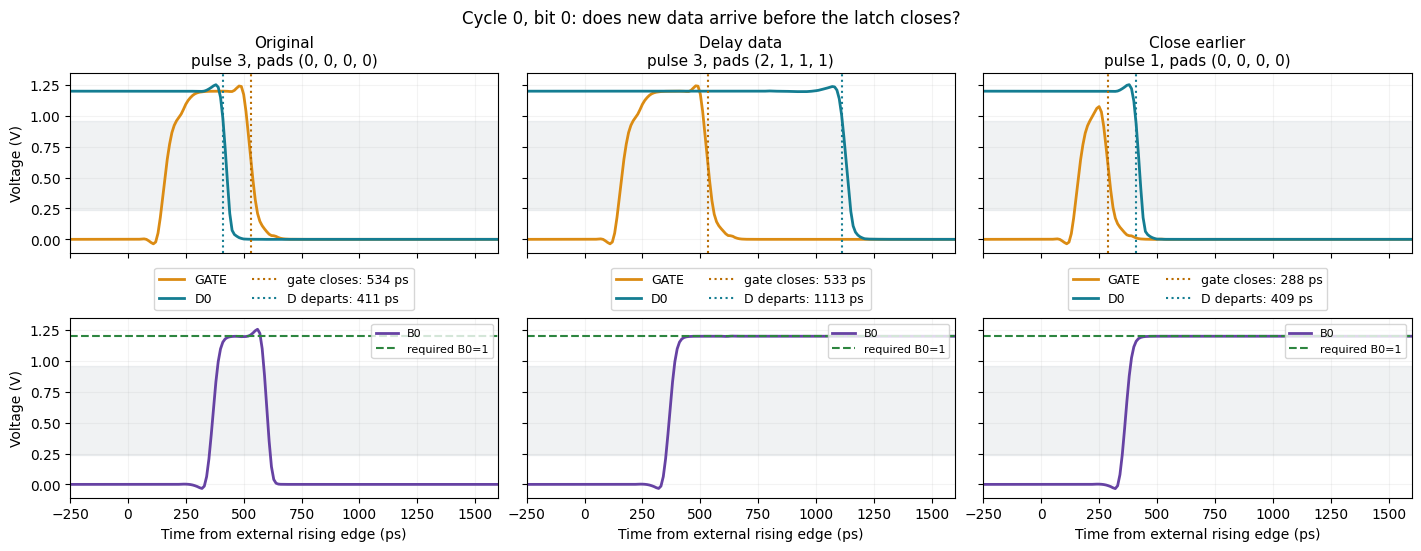

In [24]:
VIEW_DESIGN = 'Delay data'  # Select 'Delay data' or 'Close earlier' for the timing table.
BIT, CYCLE = 0, 0
VIEW_END_NS = 1.6  # Use 3.5 to include the deadline, or 9.9 for the whole valid interval.
trial = {'Delay data': padding_trial, 'Close earlier': pulse_trial}[VIEW_DESIGN]
_ = plot_experiment([('Original', failure), ('Delay data', padding_trial),
                     ('Close earlier', pulse_trial)],
                    bit=BIT, cycle=CYCLE, end_ns=VIEW_END_NS)

### Timing extraction and interpretation
The figure compares all three implementations for the selected bit and cycle.
Set `VIEW_DESIGN` to `'Delay data'` or `'Close earlier'` to select the repair
for the timing table and event-shift summary below. After changing this selection, rerun the view cell and those displays; they read the existing simulation traces.

Pulse width is measured between the gate's **50% VDD crossings**. Data departure is the first time D leaves its old valid band: below 80% for an old 1, or above 20% for an old 0. A brief glitch counts even if D returns to its original level.

$$
\Delta t_{\mathrm{observed}}=t_{\mathrm{D\ departure}}-t_{\mathrm{gate\ close}}.
$$

Positive means the measured departure occurs after closure; negative means it
occurs before closure. This identifies event order. It is **not a characterized hold margin**, because the latch's finite hold requirement has not been measured.

When D stays in its old valid band throughout the observation window, there is no departure time to subtract. The table reports that missing event explicitly.

In [25]:
timing = timing_table(trial, cycle=CYCLE)
readable = timing_view(trial, cycle=CYCLE)
gate = readable.iloc[0]
print(f"Gate: {gate['gate status']}; width = {gate['gate width at 50% (ps)']} ps; "
      f"close = {gate['gate close (ps)']} ps")
display(readable[['bit', 'old D', 'D departure (ps)',
                  'departure - close (ps)', 'separation status']].set_index('bit'))
print('Valid preparation:', timing.attrs['preparation_valid'])
print('Observation ends at', gate['observed through'], 'after the external edge.')

Gate: one valid pulse; width = 366.52 ps; close = 533.20 ps


,old D,D departure (ps),departure - close (ps),separation status
bit,,,,
0,1,1112.80,579.59,measured event separation
1,0,not observed through +9900 ps,no departure observed,no departure observed
2,0,not observed through +9900 ps,no departure observed,no departure observed
3,0,791.75,258.55,measured event separation


Valid preparation: True
Observation ends at +9900 ps after the external edge.


In [26]:
if failure['inputs'] != trial['inputs']:
    raise ValueError('Rerun the repair: the input histories differ.')
checked_index(BIT, 4, 'BIT')
before = timing_table(failure, cycle=CYCLE).iloc[BIT]
after = timing_table(trial, cycle=CYCLE).iloc[BIT]
for label, key in [('Gate closure', 'gate_close_ps'), ('D departure', 'D_departure_ps')]:
    if pd.notna(before[key]) and pd.notna(after[key]):
        shift = after[key] - before[key]
        print(f'{label} moved {abs(shift):.1f} ps ' + ('later.' if shift >= 0 else 'earlier.'))
    else:
        print(f'{label}: no pair of measured events to subtract; inspect the status above.')
print('Sequence result:', 'PASS' if transaction_table(trial).attrs['passed'] else 'FAIL')

Gate closure moved 0.3 ps earlier.
D departure moved 701.9 ps later.
Sequence result: PASS


### Returning glitches and absent transitions
For the default padding repair, select `VIEW_DESIGN = 'Delay data'`, `CYCLE = 0` and `BIT = 3`. D3 begins and ends low, yet briefly leaves the valid-low band. Its returning glitch produces a measured departure time.

Now inspect bits 1 and 2. They also begin and end low, but remain inside the band throughout the observation window. Their departure is **not observed**.
These cases have identical endpoint logic but different timing behavior.

This is why the checker and timing calculations use the full waveforms. Neither an endpoint sample nor a positive event separation alone establishes a working pipeline.

<a id="energy-comparison"></a>

## 3. Energy comparison with flip-flop storage
Both repairs may restore the pipeline boundary, but they do not add the same
circuitry. Now compare the **DFF reference, padded latch and shorter-pulse latch** on the same repeated workload.

Count energy delivered through VDD, clock, reset and all four data sources:

$$
E=-\sum_{s\in\mathrm{sources}}\int V_s(t)I_s(t)\,dt.
$$

The minus sign follows ngspice's convention that current is positive into a source's positive terminal. Returned energy retains its sign. VDD already includes pulse generators, padding, storage, logic and drivers, so those internal costs are counted once.

The integral below operates directly on the new trace samples.

In [27]:
def integrate_window(run, start, end):
    ports = [('VDD', 'i(vdd)', None), ('clock', 'i(vclk)', 'clk_src'),
             ('reset', 'i(vreset)', 'reset_src')]
    ports += [(f'data{bit}', f'i(vx{bit})', f'x{bit}_src') for bit in range(4)]
    integrate = getattr(np, 'trapezoid', None) or np.trapz
    sources = {}
    for label, current_name, voltage_name in ports:
        time, current = interval_values(run, current_name, start, end)
        voltage = (run['vdd'] if voltage_name is None
                   else interval_values(run, voltage_name, start, end)[1])
        sources[label] = float(integrate(-voltage*current, time))
    return {'sources_j': sources, 'total_j': sum(sources.values()),
            'start_s': start, 'end_s': end}

A low-energy circuit is useful only if it performs the required transactions.
The comparison therefore checks outputs and loaded clock pulses before ranking designs.
Four workload repetitions and one look-ahead input let us discard startup and compare the last two equal-phase windows. We report the last window's energy per transaction.

The two windows must agree within 0.5% in energy and within 1 mV in exported boundary states. Agreement between the windows checks that the reported energy represents repeatable operation.

In [28]:
def pulses_pass(run):
    for edge in run['edges']:
        for node in ('gate_a', 'gate_b'):
            time, gate = interval_values(run, node, edge-0.5e-9, edge+run['period']-0.1e-9)
            rises = crossing_times(time, gate, 0.5*run['vdd'], True)
            falls = crossing_times(time, gate, 0.5*run['vdd'], False)
            if not (len(rises) == len(falls) == 1 and rises[0] < falls[0]
                    and max(gate) >= 0.8*run['vdd']
                    and max(gate[0], gate[-1]) <= 0.2*run['vdd']):
                return False
    return True

In [29]:
def energy_summary(run, workload_length):
    length = workload_length
    if type(length) is not int or length < 1:
        raise ValueError('workload_length must be a positive integer.')
    workload = tuple(run['inputs'][:length])
    if tuple(run['inputs']) != workload*4 + (workload[0],):
        raise ValueError('Energy requires four workload repeats plus one look-ahead input.')
    start = run['edges'][2*length] - 0.1*run['period']
    width = length*run['period']
    windows = [integrate_window(run, start+i*width, start+(i+1)*width) for i in range(2)]
    energies = [window['total_j'] for window in windows]
    scale = max(abs(value) for value in energies)
    relative_change = abs(energies[1]-energies[0])/scale if scale else 0.0
    state_nodes = ['gate_a', 'gate_b', 'clk_src', 'reset_src', 'carry2', 'carry3']
    state_nodes += [f'{prefix}{bit}' for prefix in ('a', 'b', 'd', 'inc') for bit in range(4)]
    state_nodes += [f'x{bit}_src' for bit in range(4)]
    if run['architecture'] == 'latch':
        state_nodes += ['clk_del_a', 'clk_del_b', 'clk_del_n_a', 'clk_del_n_b']
    boundaries = start + np.arange(3)*width
    differences = {node: float(np.max(np.abs(np.diff(np.interp(
        boundaries, run['trace']['time'], run['trace'][node]))))) for node in state_nodes}
    steady = relative_change <= 0.005 and max(differences.values()) <= 0.001
    correct = transaction_table(run).attrs['passed']
    pulses = pulses_pass(run)
    return {'workload': workload, 'functional_passed': correct, 'pulses_passed': pulses,
            'steady_passed': bool(steady), 'comparison_eligible': bool(correct and steady and pulses),
            'energy_fj_per_transaction': energies[1]/length*1e15,
            'source_fj_per_transaction': {name: value/length*1e15 for name, value in windows[1]['sources_j'].items()},
            'window_energy_relative_difference': relative_change,
            'max_boundary_state_difference_v': max(differences.values()),
            'windows': windows,
            'scope': 'Signed seven-source energy; startup excluded. Stationarity covers exported states only. '
                     'A failed circuit can consume energy but is not eligible for the implementation ranking.'}

**Run the reference once for this workload.** If you change `WORKLOAD`, rerun it and both repair-energy cells. After editing a repair, rerun its timing simulation, the view and timing displays, its energy cell, and the comparison and conclusion below.

In [30]:
WORKLOAD = (0, 1, 3, 7, 15, 0, 8, 5)
workload = tuple(WORKLOAD)
if not workload:
    raise ValueError('Enter at least one input word in WORKLOAD.')
energy_inputs = workload * 4 + (workload[0],)
reference_run = simulate(energy_inputs, architecture='dff', pads=(0, 0, 0, 0))
reference = energy_summary(reference_run, len(workload))

Fresh dff simulation: pulse=3, padding=(0, 0, 0, 0), 33 inputs, 195.8 s


**Measure each repair on the reference workload.** These cells use the circuit configurations captured in the timing simulations above. They can be rerun independently.

In [31]:
padding_energy_run = simulate(reference_run['inputs'], pulse_variant=padding_trial['pulse_variant'],
                              pads=padding_trial['pads'])
padding_energy = energy_summary(padding_energy_run, len(reference['workload']))

Fresh latch simulation: pulse=3, padding=(2, 1, 1, 1), 33 inputs, 221.3 s


In [32]:
pulse_energy_run = simulate(reference_run['inputs'], pulse_variant=pulse_trial['pulse_variant'],
                            pads=pulse_trial['pads'])
pulse_energy = energy_summary(pulse_energy_run, len(reference['workload']))

Fresh latch simulation: pulse=1, padding=(0, 0, 0, 0), 33 inputs, 191.8 s


,fJ / transaction,transactions,clock pulses,steady windows
DFF,378.77,PASS,PASS,PASS
Delay data,504.99,PASS,PASS,PASS
Close earlier,410.16,PASS,PASS,PASS


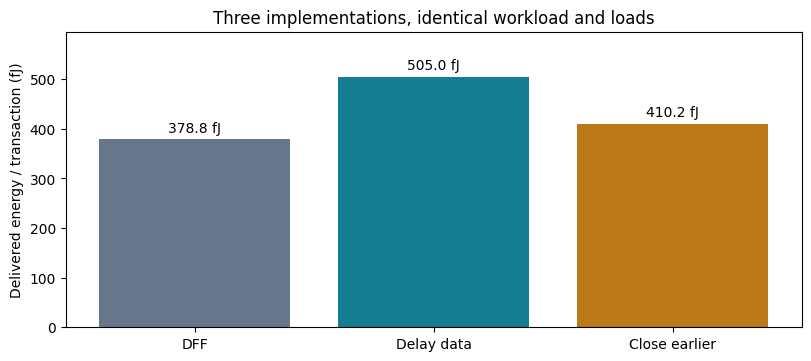

In [33]:
energy_runs = {'DFF': reference_run, 'Delay data': padding_energy_run, 'Close earlier': pulse_energy_run}
reports = {'DFF': reference, 'Delay data': padding_energy, 'Close earlier': pulse_energy}
for label, design in [('Delay data', padding_trial), ('Close earlier', pulse_trial)]:
    if any(energy_runs[label][key] != design[key] for key in ('pulse_variant', 'pads')):
        raise ValueError(f'{label} changed. Rerun its energy cell.')
for run in energy_runs.values():
    if any(run[key] != reference_run[key] for key in ('inputs', 'period', 'vdd')):
        raise ValueError('The comparison conditions differ. Rerun both repair-energy cells.')
energy_table = pd.DataFrame({label: {
    'fJ / transaction': r['energy_fj_per_transaction'],
    'transactions': 'PASS' if r['functional_passed'] else 'FAIL',
    'clock pulses': 'PASS' if r['pulses_passed'] else 'FAIL',
    'steady windows': 'PASS' if r['steady_passed'] else 'FAIL',
} for label, r in reports.items()}).T
energy_table['fJ / transaction'] = energy_table['fJ / transaction'].astype(float).round(2)
display(energy_table)
fig, ax = plt.subplots(figsize=(8, 3.5), layout='constrained')
bars = ax.bar(list(reports), [r['energy_fj_per_transaction'] for r in reports.values()],
              color=['#67768a', '#147d92', '#bc7918'])
for bar, r in zip(bars, reports.values()):
    if not r['comparison_eligible']:
        bar.set_hatch('//')
        bar.set_label('Checks failed: excluded from ranking')
ax.bar_label(bars, fmt='%.1f fJ', padding=3)
ax.margins(y=0.18)
ax.set_ylabel('Delivered energy / transaction (fJ)')
ax.set_title('Three implementations, identical workload and loads')
if not all(r['comparison_eligible'] for r in reports.values()): ax.legend()
plt.show()
plt.close(fig)

Comparing the two latch implementations reveals the energy tradeoff between the timing repairs. Comparing each with the matched DFF reference determines whether either provides an energy benefit for the tested workload.

Each local pulse generator serves four latches in this circuit. Its energy cost remains part of the implementation when padding is removed. The source breakdown below includes the energy delivered by the external data, clock and reset sources as well as VDD.

In [34]:
source_energy = pd.DataFrame({label: report['source_fj_per_transaction']
                              for label, report in reports.items()})
display(source_energy.round(3).rename_axis('Source (fJ / transaction)'))

,DFF,Delay data,Close earlier
Source (fJ / transaction),,,
VDD,375.859,502.088,407.258
clock,1.882,1.880,1.880
reset,0.000,0.000,0.000
data0,0.293,0.293,0.293
data1,0.146,0.147,0.147
data2,0.293,0.293,0.293
data3,0.293,0.293,0.293


### Numerical sensitivity
The optional cell below repeats the repair selected by `VIEW_DESIGN` with a 5 ps maximum step instead of 10 ps. Set the switch to `False` during quick exploration. The comparison tests whether the measured energy changes materially with the numerical step.

In [35]:
CHECK_SMALLER_TIMESTEP = True
if CHECK_SMALLER_TIMESTEP:
    selected_run, selected = energy_runs[VIEW_DESIGN], reports[VIEW_DESIGN]
    finer_run = simulate(selected_run['inputs'], pulse_variant=selected_run['pulse_variant'],
                         pads=selected_run['pads'], step_ps=5)
    finer = energy_summary(finer_run, len(selected['workload']))
    difference = 100 * (finer['energy_fj_per_transaction'] / selected['energy_fj_per_transaction'] - 1)
    print(f"{VIEW_DESIGN}, 5 ps: {finer['energy_fj_per_transaction']:.3f} fJ/transaction")
    print(f'Change from 10 ps: {difference:+.3f}% | Checks pass: {finer["comparison_eligible"]}')

Fresh latch simulation: pulse=3, padding=(2, 1, 1, 1), 33 inputs, 388.0 s
Delay data, 5 ps: 504.599 fJ/transaction
Change from 10 ps: -0.078% | Checks pass: True


<a id="results"></a>

## Results and design implications
The default failure results from same-cycle propagation through transparent latch banks. Padding restores the pipeline boundary by postponing new data; a shorter pulse restores it by closing the receiving latch earlier. The measured event order distinguishes these two mechanisms.

Among implementations that satisfy the defined functional and steady-window checks, energy per transaction is the comparison metric. The following summary is computed from the current simulation results.

In [36]:
eligible = {name: result for name, result in reports.items() if result['comparison_eligible']}
if len(eligible) != len(reports):
    print('At least one implementation failed a comparison check; investigate it before making a full ranking.')
if 'DFF' in eligible:
    reference_e = eligible['DFF']['energy_fj_per_transaction']
    for name in ('Delay data', 'Close earlier'):
        if name in eligible:
            change = 100 * (eligible[name]['energy_fj_per_transaction']/reference_e - 1)
            print(f'{name}: {change:+.2f}% energy relative to DFF.')
if len(eligible) == len(reports):
    choice = min(eligible, key=lambda name: eligible[name]['energy_fj_per_transaction'])
    print(f'Lowest measured energy among the passing implementations: {choice}.')
    print('Choose on complete circuit cost; simpler storage alone does not establish an energy advantage.')

Delay data: +33.33% energy relative to DFF.
Close earlier: +8.29% energy relative to DFF.
Lowest measured energy among the passing implementations: DFF.
Choose on complete circuit cost; simpler storage alone does not establish an energy advantage.


**Default run.** With the supplied circuit settings and workload, both latch repairs satisfy the transaction checks. Shortening the pulse reduces energy relative to the padded implementation, but neither repair gives an energy advantage over the DFF reference.
The result illustrates why the storage element, pulse generator and timing-repair circuitry must be evaluated together.

After changing parameters and rerunning the relevant cells, use the computed
summary above for the current results.

The editable input history, padding counts and pulse-cell selection allow the same comparison to be repeated for other design choices. The reported conclusions cover schematic simulations at TT, 25 °C and 1.2 V; they do not establish a characterized hold margin or correctness across all inputs and PVT corners.

## Sources and license
- [IHP SG13G2 standard cells and model cards](https://github.com/IHP-GmbH/IHP-Open-PDK/tree/5e6d592e4002946a4616f798c357f0f3c06cf3b6).
- [VA-Models v2.2 PSP103 binaries](https://github.com/dwarning/VA-Models/releases/tag/v2.2).
- [ngspice documentation](https://ngspice.sourceforge.io/docs.html).
- [Paik and Shin, Pulsed-Latch Circuits to Push the Envelope of ASIC Design, ISOCC 2010](https://doi.org/10.1109/SOCDC.2010.5682949).

The IHP cell netlists and parameter cards are unchanged. Third-party models retain their
upstream licenses; pulsed latches and hold padding are established techniques.

The notebook code, explanations and diagram are licensed as follows:

```text
MIT License
Copyright (c) 2026 Michael Ibrahim

Permission is hereby granted, free of charge, to any person obtaining a copy
of this software and associated documentation files (the "Software"), to deal
in the Software without restriction, including without limitation the rights
to use, copy, modify, merge, publish, distribute, sublicense, and/or sell
copies of the Software, and to permit persons to whom the Software is
furnished to do so, subject to the following conditions:

The above copyright notice and this permission notice shall be included in all
copies or substantial portions of the Software.

THE SOFTWARE IS PROVIDED "AS IS", WITHOUT WARRANTY OF ANY KIND, EXPRESS OR
IMPLIED, INCLUDING BUT NOT LIMITED TO THE WARRANTIES OF MERCHANTABILITY,
FITNESS FOR A PARTICULAR PURPOSE AND NONINFRINGEMENT. IN NO EVENT SHALL THE
AUTHORS OR COPYRIGHT HOLDERS BE LIABLE FOR ANY CLAIM, DAMAGES OR OTHER
LIABILITY, WHETHER IN AN ACTION OF CONTRACT, TORT OR OTHERWISE, ARISING FROM,
OUT OF OR IN CONNECTION WITH THE SOFTWARE OR THE USE OR OTHER DEALINGS IN THE
SOFTWARE.
```